# Bonus Option B: Triplet Validation

**Candidate Name:** Matteo Antony Mistretta

**Date:** 2026-10-17

**Environment:** Python 3.14, sentence-transformers, PyTorch 2.14 (CPU), scikit-learn 1.9 (exact versions in `requirements.txt`).

**Downloaded on first run:** the `all-MiniLM-L6-v2` model (~90 MB) is fetched from Hugging Face the first time, then cached in `~/.cache/huggingface`; it is pinned to a fixed revision.

*Validate embedding quality via triplet constraints*

## Overview

**What a triplet is.** Each row of the dataset is a *triplet* used to train the embedding model: an **anchor**, a **positive** with similar meaning, and a **negative** with different meaning (Part 1A). Training pushed the anchor's embedding *closer* to the positive's than to the negative's. A triplet is **satisfied** when this holds:

  cosine similarity(anchor, positive) **>** cosine similarity(anchor, negative)

and the **margin** is the difference between the two (positive = satisfied, negative = violated).

**Goal.** Measure how often the constraint holds, overall and per category, as a direct check of what the embedding model learned.

**Comparison.** To see what the fine-tuning added, I run the same check with a **general-purpose embedding model**, `all-MiniLM-L6-v2` from the sentence-transformers library (suggested by the README): a small, widely used model trained on general English text, never on this dataset.

**Important caveat:** the README says these triplets come from the fine-tuned model's *training* process. Its score on them is therefore **in-sample**: it shows how well the model learned its training objective, not how well it generalises to new triplets. MiniLM has never seen them, so it is a fair reference for "how much of this is common-sense meaning".

**Plan:**
1. Compute similarities and satisfaction for both models.
2. Break the results down by category, by negative difficulty and by origin (real or synthetic).
3. Visualise the similarity distributions.
4. Inspect the triplets the fine-tuned model gets wrong.
5. Compare triplet quality with Part 2's classification results.
6. Interpretation.

### Setup

**What:** load the data, the three embedding files produced by `optimized_embedder.py --include-triplets` (Part 1B), and embed the same texts with MiniLM.

**How:** the API returns vectors of length 1, so cosine similarity is a plain dot product (Part 1C). MiniLM is asked for length-1 vectors too (`normalize_embeddings=True`). Each distinct text is embedded once and looked up for every row, as in Part 1B. MiniLM produces 384 numbers per text instead of 768; that does not matter, since each model is only compared with itself.

A few harmless library messages are switched off to keep the output readable: a macOS-specific note from PyTorch, a notice that the Hugging Face download is not logged in (not needed for a public model), and a loading progress bar.

In [1]:
import logging
import time
from pathlib import Path

# Silence harmless library messages (see the text above)
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
from huggingface_hub.utils import logging as hf_logging
from transformers.utils import logging as transformers_logging
hf_logging.set_verbosity_error()
transformers_logging.set_verbosity_error(); transformers_logging.disable_progress_bar()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sentence_transformers import SentenceTransformer

sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 70)

df = pd.read_csv("data/endpoints_data.csv")
CLASSES = df["case"].value_counts().index.tolist()

A, P, N = (np.load(f"embeddings/{c}.npy") for c in ("anchor", "positive", "negative"))
print(f"Fine-tuned embeddings: {A.shape} each for anchor, positive, negative")

t0 = time.perf_counter()
minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu",
                             revision="1110a243fdf4706b3f48f1d95db1a4f5529b4d41")   # pinned revision
texts = pd.unique(pd.concat([df["anchor"], df["positive"], df["negative"]]))
lookup = dict(zip(texts, minilm.encode(list(texts), batch_size=256, normalize_embeddings=True)))
mA, mP, mN = (np.stack(df[c].map(lookup).to_numpy()) for c in ("anchor", "positive", "negative"))
print(f"MiniLM embedded {len(texts)} distinct texts in {time.perf_counter() - t0:.1f} s; {mA.shape[1]} numbers per text")

Fine-tuned embeddings: (3413, 768) each for anchor, positive, negative


MiniLM embedded 9053 distinct texts in 3.7 s; 384 numbers per text


## 1. Satisfaction rate

**What:** for every row and both models, compute the two similarities, the margin, and whether the triplet is satisfied; then summarise.

**How to read the table:** `satisfaction_rate` is the share of satisfied triplets; `mean_sim_pos` and `mean_sim_neg` are the average similarities to the positive and to the negative; `mean_margin` is their average difference, i.e. how *clearly* the model separates them, not just whether it does.

In [2]:
trip = df[["anchor", "positive", "negative", "case", "is_synthetic", "is_root_pair_similar"]].copy()
for name, (a, p, n) in {"arca": (A, P, N), "minilm": (mA, mP, mN)}.items():
    trip[f"{name}_sim_pos"] = (a * p).sum(1)
    trip[f"{name}_sim_neg"] = (a * n).sum(1)
    trip[f"{name}_margin"] = trip[f"{name}_sim_pos"] - trip[f"{name}_sim_neg"]
    trip[f"{name}_ok"] = trip[f"{name}_margin"] > 0

pd.DataFrame({
    "satisfied": [trip["arca_ok"].sum(), trip["minilm_ok"].sum()],
    "satisfaction_rate": [trip["arca_ok"].mean(), trip["minilm_ok"].mean()],
    "mean_sim_pos": [trip["arca_sim_pos"].mean(), trip["minilm_sim_pos"].mean()],
    "mean_sim_neg": [trip["arca_sim_neg"].mean(), trip["minilm_sim_neg"].mean()],
    "mean_margin": [trip["arca_margin"].mean(), trip["minilm_margin"].mean()],
}, index=["Arca fine-tuned (768 numbers)", "MiniLM general (384 numbers)"]).round(3)

,satisfied,satisfaction_rate,mean_sim_pos,mean_sim_neg,mean_margin
Arca fine-tuned (768 numbers),3406,0.998,0.903,0.006,0.898
MiniLM general (384 numbers),2920,0.856,0.594,0.276,0.318


## 2. Breakdowns

**What:** satisfaction rates for both models, and the improvement of the fine-tuned model in percentage points, split three ways:
- **by negative difficulty**: `is_root_pair_similar` = True marks *hard negatives*, negatives close in meaning to the anchor (Part 1A);
- **by origin**: real vs synthetic rows (`is_synthetic`, Part 1A);
- **by category**.

In [3]:
def rates(group_col):
    g = trip.groupby(group_col)
    out = pd.DataFrame({"triplets": g.size(), "arca": g["arca_ok"].mean(), "minilm": g["minilm_ok"].mean()})
    out["improvement_pts"] = (out["arca"] - out["minilm"]) * 100
    return out

print("By negative difficulty (True = hard negative):")
print(rates("is_root_pair_similar").round(3).to_string(), "\n")
print("By origin (True = synthetic):")
print(rates("is_synthetic").round(3).to_string(), "\n")
per_cat = rates("case").reindex(CLASSES)
print("By category:")
per_cat.sort_values("minilm").round(3)

By negative difficulty (True = hard negative):
                      triplets   arca  minilm  improvement_pts
is_root_pair_similar                                          
False                     2217  0.997   0.884           11.322
True                      1196  1.000   0.804           19.649 

By origin (True = synthetic):
              triplets   arca  minilm  improvement_pts
is_synthetic                                          
False              467  0.985   0.782           20.343
True              2946  1.000   0.867           13.272 

By category:


,triplets,arca,minilm,improvement_pts
case,,,,
COA Tool,660,1.000,0.659,34.091
Pharmacokinetic,580,0.995,0.853,14.138
Immunogenicity,200,0.990,0.880,11.000
Adverse Event,312,1.000,0.885,11.538
General Case,840,0.999,0.918,8.095
Mortality,200,0.995,0.920,7.500
Complications,221,1.000,0.932,6.787
Cost,200,1.000,0.940,6.000
Demographic,200,1.000,0.945,5.500


## 3. Similarity distributions

**What:** four charts.
- **Top row**, one per model: histograms of the similarity to the positive (green) and to the negative (red). The further apart the two shapes, the more clearly the model tells them apart; where they overlap, some triplets are violated.
- **Bottom left**: the distribution of margins, for easy (solid) and hard (dashed) negatives, as smoothed curves. Anything **left of the vertical line at 0** is a violated triplet.
- **Bottom right**: satisfaction rate by category for both models.

Below the charts, I count how many fine-tuned similarities fall between 0.4 and 0.75, where its two distributions appear to separate.

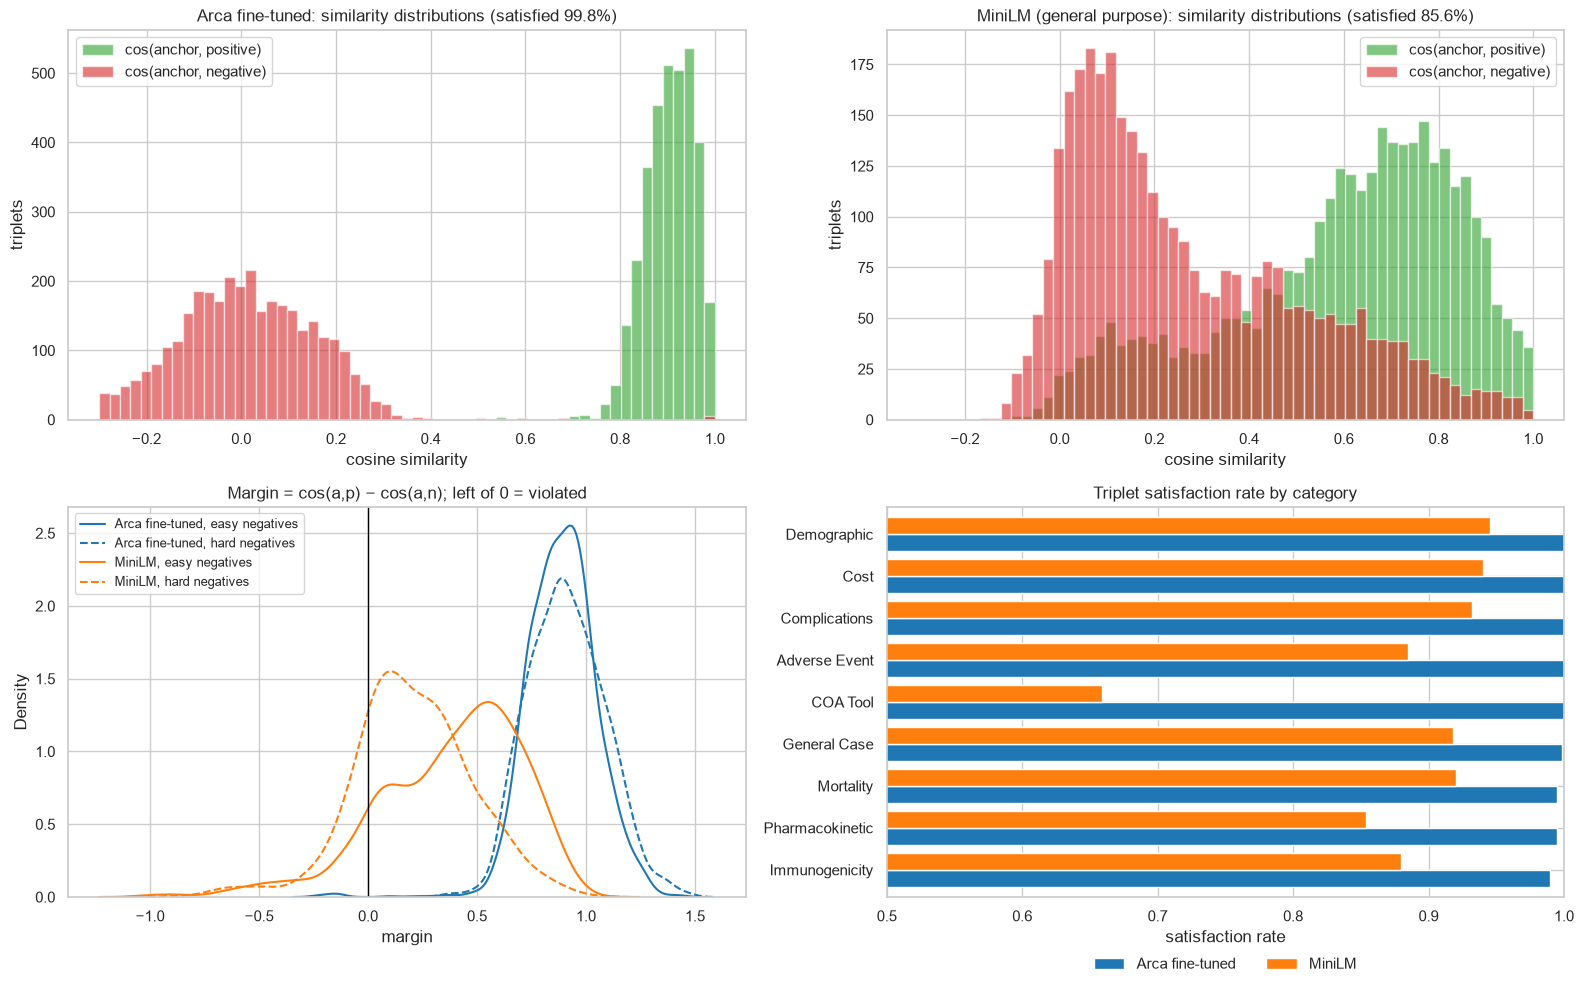

Fine-tuned similarities between 0.4 and 0.75: 26 of 3413 to positives, 12 to negatives


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
bins = np.linspace(-0.3, 1.0, 60)
for ax, name, title in [(axes[0, 0], "arca", "Arca fine-tuned"), (axes[0, 1], "minilm", "MiniLM (general purpose)")]:
    ax.hist(trip[f"{name}_sim_pos"], bins=bins, alpha=0.6, label="cos(anchor, positive)", color="tab:green")
    ax.hist(trip[f"{name}_sim_neg"], bins=bins, alpha=0.6, label="cos(anchor, negative)", color="tab:red")
    ax.set(title=f"{title}: similarity distributions (satisfied {trip[f'{name}_ok'].mean():.1%})",
           xlabel="cosine similarity", ylabel="triplets"); ax.legend()

ax = axes[1, 0]
for name, label, color in [("arca", "Arca fine-tuned", "tab:blue"), ("minilm", "MiniLM", "tab:orange")]:
    for hard, ls in [(False, "-"), (True, "--")]:
        m = trip["is_root_pair_similar"] == hard
        sns.kdeplot(trip.loc[m, f"{name}_margin"], ax=ax, color=color, ls=ls,
                    label=f"{label}, {'hard' if hard else 'easy'} negatives")
ax.axvline(0, color="black", lw=1)
ax.set(title="Margin = cos(a,p) − cos(a,n); left of 0 = violated", xlabel="margin"); ax.legend(fontsize=9)

ax = axes[1, 1]
(per_cat[["arca", "minilm"]].sort_values("arca").rename(columns={"arca": "Arca fine-tuned", "minilm": "MiniLM"})
   .plot.barh(ax=ax, color=["tab:blue", "tab:orange"], width=0.8))
ax.set(xlim=(0.5, 1.0), title="Triplet satisfaction rate by category", xlabel="satisfaction rate", ylabel="")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "bonusB_triplets.png", dpi=120); plt.show()

in_gap = lambda s: ((s > 0.4) & (s < 0.75)).sum()
print(f"Fine-tuned similarities between 0.4 and 0.75: {in_gap(trip['arca_sim_pos'])} of {len(trip)} to positives, "
      f"{in_gap(trip['arca_sim_neg'])} to negatives")

## 4. The triplets the fine-tuned model gets wrong

**What:** list every violated triplet of the fine-tuned model, with both similarities, and count those where the negative text is identical to the anchor.

**Why:** a handful of violations out of 3,413 is too few for statistics; reading them tells whether they are model mistakes or something else.

In [5]:
viol = trip[~trip["arca_ok"]].sort_values("arca_margin")
print(f"Violations: {len(viol)} of {len(trip)}")
print(f"  of which the negative is the same text as the anchor: {(viol['negative'] == viol['anchor']).sum()}")
print(f"Rows in the whole dataset whose negative equals the anchor: {(trip['negative'] == trip['anchor']).sum()}")
print(f"Triplets MiniLM gets right but the fine-tuned model gets wrong: {(trip['minilm_ok'] & ~trip['arca_ok']).sum()}; "
      f"the opposite: {(trip['arca_ok'] & ~trip['minilm_ok']).sum()}")
viol[["anchor", "positive", "negative", "case", "arca_sim_pos", "arca_sim_neg"]].round(3)

Violations: 7 of 3413
  of which the negative is the same text as the anchor: 7
Rows in the whole dataset whose negative equals the anchor: 7
Triplets MiniLM gets right but the fine-tuned model gets wrong: 0; the opposite: 486


,anchor,positive,negative,case,arca_sim_pos,arca_sim_neg
240,Anti-HPV-16,Drug bioavailability assessment,Anti-HPV-16,Pharmacokinetic,0.760,1.0
543,periprocedural and late myocardial infarction (MI),Anti-HIV Antibody Response,periprocedural and late myocardial infarction (MI),Immunogenicity,0.791,1.0
2209,AVR,30-day post-operative mortality,AVR,Mortality,0.814,1.0
1739,Perioperative morbidity,AUC of levonorgestrel in plasma,Perioperative morbidity,Pharmacokinetic,0.846,1.0
120,markedly,Days without depression,markedly,General Case,0.850,1.0
2395,Postoperative bleeding (mL),clearance of lamotrigine metabolites,Postoperative bleeding (mL),Pharmacokinetic,0.866,1.0
1844,SSNA,Anti-Drug Antibodies against Tremelimumab,SSNA,Immunogenicity,0.881,1.0


**Observations - violations**
- The fine-tuned model violates only **7 of 3,413 triplets**, and in **all 7 the negative is the same text as the anchor** (e.g. anchor *"AVR"*, negative *"AVR"*), so the similarity to the negative is 1.0 by construction and no model could satisfy them. These are the only 7 such rows in the dataset (output above). **They are data errors, not model errors**: on the valid triplets, the fine-tuned model is right 100% of the time. MiniLM never gets right a triplet the fine-tuned model gets wrong, while the opposite happens 486 times.
- **These rows look corrupted beyond the negative.** In each one the positive is unrelated to the anchor, and the category fits the **positive**, not the anchor:
  - *"Anti-HPV-16"* → *"Drug bioavailability assessment"*, labelled Pharmacokinetic;
  - *"AVR"* → *"30-day post-operative mortality"*, labelled Mortality;
  - *"Postoperative bleeding (mL)"* → *"clearance of lamotrigine metabolites"*, labelled Pharmacokinetic;

  and similarly for the other four (table above). The most likely explanation is a **column shift during dataset construction**: these rows' anchor column holds the text that belongs in their negative column.
- **This explains a Part 1A finding**: *"AVR"* labelled Mortality was one of the suspicious labels found there. It is not a labelling mistake on a real endpoint but one of these corrupted rows.
- **Implication for Part 2:** these 7 rows are part of the data the classifier was trained and evaluated on, with an anchor that does not match its label. Removing them would be a first, concrete label-cleaning step (Part 2's improvement #3).

## 5. Triplet quality vs classification quality

**What:** compare, category by category, the fine-tuned model's triplet satisfaction with the test F1 of the Part 2 classifier.

**How:** so that this notebook is self-contained, I load the saved Part 2 model (`models/endpoint_classifier.pt`) and rebuild the same test set with the same code and seed as Part 2 (a stratified, grouped split; Part 2, Section 1), then compute each category's F1. The network definition must match the one used in Part 2 to load its weights. I also recompute the Part 1C kNN purity, which Part 2 found to predict F1 well (r = 0.93), as a reference. *r* is the correlation across the 9 categories: close to 1 = aligned, close to 0 = no relation, negative = opposite.

In [6]:
import torch
import torch.nn as nn
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors

# Same network definition as Part 2, needed to load the saved weights
class EndpointClassifier(nn.Module):
    def __init__(self, in_dim=768, hidden=(512, 128), n_classes=9, dropout=0.3, input_dropout=0.1):
        super().__init__()
        layers, prev = [nn.Dropout(input_dropout)], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

saved = torch.load("models/endpoint_classifier.pt")
model = EndpointClassifier(hidden=saved["config"]["hidden"])
model.load_state_dict(saved["state_dict"]); model.eval()
assert saved["classes"] == CLASSES

# Same test set as Part 2 (seed 42): one fold of 7 of a stratified group k-fold, deduplicated
y_all = df["case"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
groups = df["anchor"].str.lower().str.strip().to_numpy()
_, test_rows = next(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
                    .split(np.arange(len(df)), y_all, groups))
test_idx = df.iloc[test_rows].drop_duplicates(["anchor", "case"]).index.to_numpy()
with torch.no_grad():
    pred = model(torch.from_numpy(A[test_idx].astype(np.float32))).argmax(1).numpy()
print(f"Rebuilt Part 2 test set: {len(test_idx)} endpoints; accuracy {(pred == y_all[test_idx]).mean():.3f}")

uniq = df.drop_duplicates(["anchor", "case"])
E, yu = A[uniq.index], y_all[uniq.index]
_, nn_idx = NearestNeighbors(n_neighbors=11, metric="cosine").fit(E).kneighbors(E)
purity = pd.Series((yu[nn_idx[:, 1:]] == yu[:, None]).mean(1)).groupby(yu).mean().to_numpy()

compare = pd.DataFrame({"triplet_satisfaction": per_cat["arca"].to_numpy(),
                        "knn_purity_1C": purity,
                        "part2_test_f1": f1_score(y_all[test_idx], pred, average=None)}, index=CLASSES)
r_trip = np.corrcoef(compare["triplet_satisfaction"], compare["part2_test_f1"])[0, 1]
r_pur = np.corrcoef(compare["knn_purity_1C"], compare["part2_test_f1"])[0, 1]
print(f"Correlation with Part 2 test F1: triplet satisfaction r = {r_trip:.2f} | kNN purity r = {r_pur:.2f}")
compare.sort_values("part2_test_f1", ascending=False).round(3)

Rebuilt Part 2 test set: 398 endpoints; accuracy 0.711
Correlation with Part 2 test F1: triplet satisfaction r = -0.14 | kNN purity r = 0.93


,triplet_satisfaction,knn_purity_1C,part2_test_f1
COA Tool,1.000,0.767,0.831
Pharmacokinetic,0.995,0.736,0.820
Cost,1.000,0.701,0.769
Mortality,0.995,0.647,0.737
Adverse Event,1.000,0.648,0.708
Immunogenicity,0.990,0.599,0.651
Complications,1.000,0.450,0.640
General Case,0.999,0.399,0.589
Demographic,1.000,0.360,0.400


**Observations - triplets vs classification**
- **Triplet satisfaction does not predict classification quality** (output above): across the 9 categories the correlation with Part 2's test F1 is **r = −0.14**, versus **r = 0.93** for the Part 1C kNN purity. Demographic and General Case satisfy 100% and 99.9% of their triplets, yet they are the two worst-classified categories (F1 0.400 and 0.589).
- The reason is the distinction noted in Part 1A's domain background: the triplets teach **"same meaning or not"**, while classification needs **"same category or not"**. Two wordings of the same demographic endpoint can be perfectly close to each other (satisfying their triplet) while sitting in a neighbourhood full of General Case endpoints (hurting classification).

## 6. Interpretation

**Satisfaction rates.** The fine-tuned model satisfies **99.8%** of the triplets (3,406 of 3,413) versus **85.6%** for the general-purpose MiniLM, a **14.2-point improvement** (Section 1). The margins show the difference even more clearly: on average the fine-tuned model places positives at a similarity of 0.90 and negatives at 0.01 (mean margin **0.90**), while MiniLM's averages are 0.59 and 0.28 (mean margin **0.32**). In the histograms, the fine-tuned model's two distributions are almost completely separated: only 38 of its 6,826 similarities fall between 0.4 and 0.75 (Section 3), while MiniLM's overlap widely. Fine-tuning made the model not just correct but **confident** on these pairs. The 7 remaining violations are corrupted rows, not model errors (Section 4).

**Where fine-tuning helps most.** The fine-tuned model's per-category rates are all ≥ 99%, so they do not discriminate; MiniLM's do (Section 2):
- **COA Tool is by far the hardest for a general model (65.9%)**, giving the largest fine-tuning gain (**+34 points**). COA triplets often pair an instrument's acronym with its full name (*"FKSI-DRS"* ↔ *"Functional Assessment of Cancer Therapy- Kidney Symptom Index- Disease related Symptoms"*), which requires domain knowledge a general model lacks. This matches the README's note that COA Tool data received special augmentation during training.
- **Hard negatives** (`is_root_pair_similar` = True) are clearly harder for MiniLM (80.4% vs 88.4% for easy ones), **confirming the Part 1A interpretation of that flag**, while the fine-tuned model gets all of them right (+19.6 points).
- MiniLM also does worse on **real rows** (78.2%) than on synthetic ones (86.7%), plausibly because real endpoints are messier (truncations, acronyms, Part 1A); the fine-tuned model is above 98% on both.

**What this says about embedding quality.** Two caveats limit what "almost 100%" means:
1. These are the model's **training triplets**, so this is in-sample performance; the near-perfect separation is typical of pairs a model was trained on. A held-out set of new triplets would be needed to measure how well it generalises.
2. The triplet task (*"is this paraphrase closer than that unrelated text?"*) is **easier than, and different from**, category classification.

Consistently, triplet satisfaction has **no relationship with Part 2's per-category performance (r = −0.14)**, while the Part 1C neighbourhood purity predicts it well (r = 0.93) (Section 5). **Triplet satisfaction confirms that the model learned paraphrase similarity, not that the space is organised by category.** For classification, category-level neighbourhood metrics are the more useful quality signal. A natural next step to improve Part 2 would be training the embedding model with objectives that use the categories directly, e.g. triplets whose negatives come from *easily confused categories* (a Demographic anchor with a General Case negative), and removing the 7 corrupted rows (Section 4).